EXAMPLE CODE FOR CONTROLLING TRANSLATION STAGE, PICOSCOPE, HYDRAHARP, LASER AND FILTERWHEEL.

In [2]:
import time
import ctypes as ct
import os
import sys
import matplotlib.pyplot as plt
from datetime import datetime
import numpy as np
from picosdk.ps6000 import ps6000 as ps
from picosdk.functions import adc2mV, assert_pico_ok
from ctypes import c_int16, c_int32, byref, c_char_p,c_float
import Components as comp
import socket
import threading

%load_ext autoreload
%autoreload 2

if socket.gethostname() == "ph-photonbec5":
    sys.path.append(r"D:/Control/PythonPackages/")

components = dict()

#filter_wheel = comp.FilterWheel(allowed_filter_positions=[0, 1, 2, 3, 4, 5])
laser = comp.Toptica_Laser()

def save_hh_data(data, binning, offset, tacq,laser_power  = 0, base_directory='D:/Data'):
    year = datetime.now().strftime('%Y')
    year_month = datetime.now().strftime('%Y%m')
    year_month_day = datetime.now().strftime('%Y%m%d')
    folder_path = os.path.join(base_directory, year, year_month, year_month_day, "g2")
    os.makedirs(folder_path, exist_ok=True)
    timestamp = datetime.now().strftime('%H%M%S')  # Using HHMMSS format for timestamp
    filename = f"hh_data_{timestamp}_bin{binning}_offset{offset}_tacq{tacq}_power{laser_power:.5f}.txt"
    file_path = os.path.join(folder_path, filename)
    with open(file_path, mode='w') as file:
        file.write("Index\tCounts\n")  # Header row
        for index, count in enumerate(data):
            file.write(f"{index}\t{count}\n")

    return file_path

def save_arrays(channel_data, time_array, stage_position, laser_power, base_directory='D:/Data'):
    year = datetime.now().strftime('%Y')
    year_month = datetime.now().strftime('%Y%m')
    year_month_day = datetime.now().strftime('%Y%m%d')
    folder_path = os.path.join(base_directory, year, year_month, year_month_day, "g1")
    os.makedirs(folder_path, exist_ok=True)
    timestamp = datetime.now().strftime('%H%M%S')  # Using HHMMSS format for timestamp
    for channel, voltage_array in channel_data.items():
        filename_voltage = f"pbec_{timestamp}_{stage_position}_{laser_power}_channel{channel}.txt"
        array_path_voltage = os.path.join(folder_path, filename_voltage)
        np.savetxt(array_path_voltage, voltage_array, fmt='%0.4f')
    filename_time = f"pbec_{timestamp}_{stage_position}_{laser_power}_Time.txt"
    time_path = os.path.join(folder_path, filename_time)
    np.savetxt(time_path, time_array, fmt='%0.4f')

def get_picoscope_data(channels=[0],analogue_offset=0,trig=0,trigsource=0,trigthresh=64,trigdir=2,trigdelay=0,trigms=1000,preTriggerSamples=2500,postTriggerSamples=2500,timebase=8,live_plot=False):
    status = {}
    chandle = c_int16()
    serial = c_char_p()  # Leave serial empty for single device
    status["openunit"] = ps.ps6000OpenUnit(byref(chandle), serial)
    assert status["openunit"] == 0, f"Failed to open PicoScope 6407, error code: {status['openunit']}"
    channel_mapping = {
        0: 'PS6000_CHANNEL_A',
        1: 'PS6000_CHANNEL_B',
        2: 'PS6000_CHANNEL_C',
        3: 'PS6000_CHANNEL_D'
    }
    buffers = {}
    chARange = ps.PS6000_RANGE['PS6000_100MV']  # ±100 mV range, the only range available for PicoScope 6407
    for ch in channels:
        if ch not in channel_mapping:
            raise ValueError("Invalid channel number. Must be 0, 1, 2, or 3.")
        channel = ps.PS6000_CHANNEL[channel_mapping[ch]]
        enabled = 1  # 1 for enabling
        coupling_type = ps.PS6000_COUPLING['PS6000_DC_50R']  # Only DC 50Ω coupling for PicoScope 6407
        bandwidth = ps.PS6000_BANDWIDTH_LIMITER['PS6000_BW_FULL']  # Full bandwidth
        status[f"set_channel_{ch}"] = ps.ps6000SetChannel(
            chandle, channel, enabled, coupling_type, chARange, analogue_offset, bandwidth
        )
        assert status[f"set_channel_{ch}"] == 0, f"Error in setting channel {ch}: {status[f'set_channel_{ch}']}"
        buffers[ch] = {
            'max': (c_int16 * (preTriggerSamples + postTriggerSamples))(),
            'min': (c_int16 * (preTriggerSamples + postTriggerSamples))()  # Used for downsampling
        }
        status[f"setDataBuffers_{ch}"] = ps.ps6000SetDataBuffers(
            chandle, channel, byref(buffers[ch]['max']), byref(buffers[ch]['min']), preTriggerSamples + postTriggerSamples, 0
        )
        assert_pico_ok(status[f"setDataBuffers_{ch}"])
    status["trigger"] = ps.ps6000SetSimpleTrigger(
        chandle, trig, trigsource, trigthresh, trigdir, trigdelay, trigms
    )
    assert_pico_ok(status["trigger"])
    maxSamples = preTriggerSamples + postTriggerSamples
    timeIntervalns = c_float()
    returnedMaxSamples = c_int32()
    status["getTimebase2"] = ps.ps6000GetTimebase2(
        chandle, timebase, maxSamples, byref(timeIntervalns), 1, byref(returnedMaxSamples), 0
    )
    assert_pico_ok(status["getTimebase2"])
    status["runBlock"] = ps.ps6000RunBlock(
        chandle, preTriggerSamples, postTriggerSamples, timebase, 0, None, 0, None, None
    )
    assert_pico_ok(status["runBlock"])
    ready = c_int16(0)
    while ready.value == 0:
        status["isReady"] = ps.ps6000IsReady(chandle, byref(ready))
    overflow = c_int16()
    cmaxSamples = c_int32(maxSamples)
    status["getValues"] = ps.ps6000GetValues(
        chandle, 0, byref(cmaxSamples), 1, 0, 0, byref(overflow)
    )
    assert_pico_ok(status["getValues"])
    maxADC = c_int16(32512)
    channel_data = {}
    for ch in channels:
        adc2mV_buffer = adc2mV(buffers[ch]['max'], chARange, maxADC)
        channel_data[ch] = adc2mV_buffer
    time = np.linspace(0, (cmaxSamples.value - 1) * timeIntervalns.value, cmaxSamples.value) # Create time data
    if live_plot:
        plt.figure(figsize=(5,5))
        for ch in channels:
            plt.plot(time, channel_data[ch][:], label=f"Channel {channel_mapping[ch]}")
        plt.xlabel('Time (ns)')
        plt.ylabel('Voltage (mV)')
        plt.title("PicoScope Data Capture on Multiple Channels")
        plt.legend()
        plt.grid()
        plt.show()
    status["stop"] = ps.ps6000Stop(chandle)
    assert_pico_ok(status["stop"])
    ps.ps6000CloseUnit(chandle) # Close unit (disconnect the scope)
    return channel_data, time # Return channel data and time for further processing

def closeDevices():
    MAXDEVNUM = 8
    if os.name == "nt":
        hhlib = ct.WinDLL("hhlib.dll")
    else:
        hhlib = ct.CDLL("libhh400.so")
    for i in range(0, MAXDEVNUM):
        hhlib.HH_CloseDevice(ct.c_int(i))
    sys.exit(0)

def get_hh_data(binning,offset,tacq,live_plot=False):
    LIB_VERSION   = "3.0"
    MAXDEVNUM     = 8
    MODE_HIST     = 0
    MAXLENCODE    = 6
    HHMAXINPCHAN  = 8
    MAXHISTLEN    = 65536
    FLAG_OVERFLOW = 0x001

    syncDivider        = 1 # You can change this
    syncChannelOffset  = 0 # You can change this (in ps, like a cable delay)
    inputChannelOffset = 0 # You can change this (in ps, like a cable delay)
    syncCFDZeroCross   = 10 # You can change this (in mV)
    syncCFDLevel       = 50 # You can change this (in mV)
    inputCFDZeroCross  = 10 # You can change this (in mV)
    inputCFDLevel      = 50 # You can change this (in mV)

    counts       = [(ct.c_uint * MAXHISTLEN)() for i in range(0, HHMAXINPCHAN)]
    dev          = []
    libVersion   = ct.create_string_buffer(b"", 8)
    hwSerial     = ct.create_string_buffer(b"", 8)
    hwPartno     = ct.create_string_buffer(b"", 8)
    hwVersion    = ct.create_string_buffer(b"", 8)
    hwModel      = ct.create_string_buffer(b"", 16)
    errorString  = ct.create_string_buffer(b"", 40)
    numChannels  = ct.c_int()
    histLen      = ct.c_int()
    resolution   = ct.c_double()
    syncRate     = ct.c_int()
    countRate    = ct.c_int()
    flags        = ct.c_int()
    warnings     = ct.c_int()
    warningstext = ct.create_string_buffer(b"", 16384)

    if os.name == "nt":
        hhlib = ct.WinDLL("hhlib.dll")
    else:
        hhlib = ct.CDLL("libhh400.so")

    def tryfunc(retcode, funcName, measRunning=False):
        if retcode < 0:
            hhlib.HH_GetErrorString(errorString, ct.c_int(retcode))
            print("HH_%s error %d (%s). Aborted." % (funcName, retcode,\
                  errorString.value.decode("utf-8")))
            closeDevices()

    hhlib.HH_GetLibraryVersion(libVersion)

    for i in range(0, MAXDEVNUM):
        retcode = hhlib.HH_OpenDevice(ct.c_int(i), hwSerial)
        if retcode == 0:

            dev.append(i)
        # else:
        #     if retcode == -1: # HH_ERROR_DEVICE_OPEN_FAIL
        #         #print("  %1d        no device" % i)
        #     else:
        #         hhlib.HH_GetErrorString(errorString, ct.c_int(retcode))
        #         print("  %1d        %s" % (i, errorString.value.decode("utf8")))
        #
    if len(dev) < 1:
        print("No device available.")
        closeDevices()

    tryfunc(hhlib.HH_Initialize(ct.c_int(dev[0]), ct.c_int(MODE_HIST), ct.c_int(0)),\
            "Initialize")

    tryfunc(hhlib.HH_GetHardwareInfo(dev[0], hwModel, hwPartno, hwVersion),\
            "GetHardwareInfo")

    tryfunc(hhlib.HH_GetNumOfInputChannels(ct.c_int(dev[0]), byref(numChannels)),\
            "GetNumOfInputChannels")

    tryfunc(hhlib.HH_Calibrate(ct.c_int(dev[0])), "Calibrate")
    tryfunc(hhlib.HH_SetSyncDiv(ct.c_int(dev[0]), ct.c_int(syncDivider)), "SetSyncDiv")

    tryfunc(hhlib.HH_SetSyncCFD(ct.c_int(dev[0]), ct.c_int(syncCFDLevel),\
                                ct.c_int(syncCFDZeroCross)),\
            "SetSyncCFD")

    tryfunc(hhlib.HH_SetSyncChannelOffset(ct.c_int(dev[0]), ct.c_int(syncChannelOffset)),\
            "SetSyncChannelOffset")

    for i in range(0, numChannels.value):
        tryfunc(hhlib.HH_SetInputCFD(ct.c_int(dev[0]), ct.c_int(i), ct.c_int(inputCFDLevel),\
                                     ct.c_int(inputCFDZeroCross)),\
                "SetInputCFD")

        tryfunc(hhlib.HH_SetInputChannelOffset(ct.c_int(dev[0]), ct.c_int(i),\
                                           ct.c_int(inputChannelOffset)),\
            "SetInputChannelOffset")

    tryfunc(hhlib.HH_SetHistoLen(ct.c_int(dev[0]), ct.c_int(MAXLENCODE), byref(histLen)),\
            "SetHistoLen")


    tryfunc(hhlib.HH_SetBinning(ct.c_int(dev[0]), ct.c_int(binning)), "SetBinning")
    tryfunc(hhlib.HH_SetOffset(ct.c_int(dev[0]), ct.c_int(offset)), "SetOffset")
    tryfunc(hhlib.HH_GetResolution(ct.c_int(dev[0]), byref(resolution)), "GetResolution")
    #print("Resolution is %1.1lfps" % resolution.value)

    time.sleep(0.4)

    tryfunc(hhlib.HH_GetSyncRate(ct.c_int(dev[0]), byref(syncRate)), "GetSyncRate")
    #print("\nSyncrate=%1d/s" % syncRate.value)

    for i in range(0, numChannels.value):
        tryfunc(hhlib.HH_GetCountRate(ct.c_int(dev[0]), ct.c_int(i), byref(countRate)),\
                "GetCountRate")
        #print("Countrate[%1d]=%1d/s" % (i, countRate.value))

    # New from v1.2: after getting the count rates you can check for warnings
    tryfunc(hhlib.HH_GetWarnings(ct.c_int(dev[0]), byref(warnings)), "GetWarnings")
    if warnings.value != 0:
        hhlib.HH_GetWarningsText(ct.c_int(dev[0]), warningstext, warnings)
        #print("\n\n%s" % warningstext.value.decode("utf-8"))

    tryfunc(hhlib.HH_SetStopOverflow(ct.c_int(dev[0]), ct.c_int(0), ct.c_int(10000)),\
            "SetStopOverflow") # for example only

    tryfunc(hhlib.HH_GetSyncRate(ct.c_int(dev[0]), byref(syncRate)), "GetSyncRate")
    #print("Syncrate=%1d/s" % syncRate.value)

    for i in range(0, numChannels.value):
        tryfunc(hhlib.HH_GetCountRate(ct.c_int(dev[0]), ct.c_int(i), byref(countRate)),\
                "GetCountRate")
        #print("Countrate[%1d]=%1d/s" % (i, countRate.value))

    tryfunc(hhlib.HH_StartMeas(ct.c_int(dev[0]), ct.c_int(tacq)), "StartMeas") #MEAS STARTS HERE !!!!!!!!
    #print("\nMeasuring for %1d milliseconds..." % tacq)

    ctcstatus = ct.c_int(0)
    while ctcstatus.value == 0:
        tryfunc(hhlib.HH_CTCStatus(ct.c_int(dev[0]), byref(ctcstatus)),\
                "CTCStatus")

    tryfunc(hhlib.HH_StopMeas(ct.c_int(dev[0])), "StopMeas")

    for i in range(0, numChannels.value):
        tryfunc(hhlib.HH_GetHistogram(ct.c_int(dev[0]), byref(counts[i]),\
                                  ct.c_int(i), ct.c_int(0)),\
            "GetHistogram")

        integralCount = 0
        for j in range(0, histLen.value):
            integralCount += counts[i][j]

        #print("  Integralcount[%1d]=%1.0lf" % (i,integralCount))

    tryfunc(hhlib.HH_GetFlags(ct.c_int(dev[0]), byref(flags)), "GetFlags")

    if flags.value & FLAG_OVERFLOW > 0:
        print("  Overflow.")

    if live_plot:
        plt.plot(counts[0])
        plt.show()
    return(counts[0])

def run_g1(position_list,number_of_measurements,power,channels,time_range,preSamples,postSamples,plot_flag,n_avg,DC,filter_positions,stage):

    stage.set(position_list[0])
    visibilities = []
    time.sleep(5)
    try:

        if power*1000 in filter_positions:
                filter_position = filter_positions[power*1000]
                filter_wheel.set(filter_position)  # Set the filter position accordingly
                print(f'Filter position set to: {filter_position+1} for power {power*1000}')
        real_positions =[]

        for k in range(len(position_list)):
            stage.set(position_list[k])
            position = stage.get_position()
            real_positions.append(position)

            for k in range(number_of_measurements):
                #print('here 1')
                a = get_picoscope_data(channels,live_plot=plot_flag,timebase = time_range, preTriggerSamples=preSamples,postTriggerSamples=postSamples)
                #print('here 2')
                Voltages = a[0]
                Timing = a[1]
                chA = np.abs(np.array(a[0][0]))
                #chB = np.abs(np.array(a[0][1]))
                #bg = 0.001
                #chC = (chA-DC)/(chB-bg)
                highest_vals = heapq.nlargest(n_avg, chA)
                lowest_vals = heapq.nsmallest(n_avg, chA)
                Imax = np.mean(highest_vals)
                Imin = np.mean(lowest_vals)
                visibility = (Imax-Imin)/(Imax+Imin)
                visibilities.append(visibility)
                save_arrays(Voltages, Timing, position,power*1000)
                #print('Now at Position : ', position, ' / Visibility : ', visibility)
            time.sleep(1)
            #print('here 3')
        if plot_flag:
            plt.plot(real_positions,visibilities,'o')
            plt.xlabel('stage position')
            plt.ylabel('visibilities')
            plt.show()
            print(real_positions,visibilities)
    except:
        print('An exception occured')



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
%load_ext autoreload
%autoreload 2
import heapq
import time

if socket.gethostname() == "ph-photonbec5":
    sys.path.append("D:/Control/PythonPackages/")
    sys.path.append("D:/Control/PiezoController/")

#_________________________________________________________G1 PARAMETERS : CHANGE HERE____________________________________________________________
position_list = np.arange(0, 250, 10)
number_of_measurements = 1 # Amount of pics to take at each position of the stage
power_list=np.arange(9.9,10,0.01)/1000
#power_list=np.append(np.arange(9.6,9.75,0.05),np.arange(9.8,10.02,0.02))/1000
channels = [0,1]  # Channel A, B
time_range = 200
preSamples = 0
postSamples = 97700
plot_flag_g1 = False # If you want to live monitor the data during the acquisition
n_avg = 200 # Number of points over which to perform averaging for Imax and Imin
DC = 1
filter_positions = { # Preset the filter position for each power value - Need to be done manually, do it everytime before taking measurements
    45:0,
    57:1,
    75:2}
#__________________________________________________________G2 PARAMETERS : CHANGE HERE____________________________________________
binning= 8 # You can change this
offset = 0
tacq = 60000 # Measurement time in millisec, you can change this
plot_flag_g2 = True




#__________________________________________________________MEASUREMENT STARTS HERE____________________________________________
with comp.Translation_Stage() as stage:
    for power in power_list:
        laser.set(power)
        def g2():
            print("Starting g2")
            data = get_hh_data(binning, offset, tacq, plot_flag_g2)
            save_hh_data(data, binning, offset, tacq,power*1000)
            print("Finished g2")
        def g1():
            print("Starting g1")
            run_g1(position_list, number_of_measurements, power, channels, time_range,
                   preSamples, postSamples, plot_flag_g1, n_avg, DC, filter_positions,stage)
            print("Finished g1")
        thread1 = threading.Thread(target=g1)
        thread2 = threading.Thread(target=g2)
        thread1.start()
        thread2.start()
        thread1.join()
        thread2.join()
        print(f"Iteration for power {power*1000} mW complete.\n")
    closeDevices()
    laser.set(0)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


ThorlabsBackendError: backend exception: D2XXException(2) ('Device Not Found')

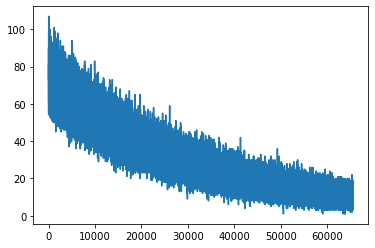

'D:/Data\\2026\\202607\\20260706\\g2\\hh_data_115300_bin8_offset0_tacq2000_power0.00000.txt'

In [4]:
#TESTING G2 PARAMETERS

plot_flag_g2 = True
binning= 8 # You can change this
offset = 0
tacq = 2000 # Measurement time in millisec, you can change this


data = get_hh_data(binning, offset, tacq,plot_flag_g2)
save_hh_data(data, binning, offset, tacq)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


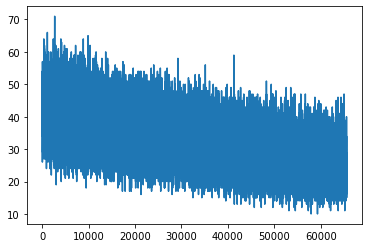

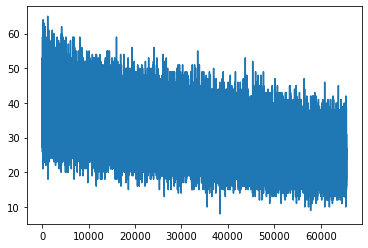

KeyboardInterrupt: 

In [5]:
%load_ext autoreload
%autoreload 2
import heapq
import time

if socket.gethostname() == "ph-photonbec5":
    sys.path.append("D:/Control/PythonPackages/")
    sys.path.append("D:/Control/PiezoController/")



#power_list=np.append(np.arange(9,10.1,0.1),np.arange(10.15,10.4,0.05))/1000
power_list=np.arange(10.35,10.7,0.025)/1000
#__________________________________________________________G2 PARAMETERS : CHANGE HERE____________________________________________
binning= 8 # You can change this
offset = 0
tacq = 30000 # Measurement time in millisec, you can change this
plot_flag_g2 = True

#__________________________________________________________MEASUREMENT STARTS HERE____________________________________________
for power in power_list:
    laser.set(power)
    data = get_hh_data(binning, offset, tacq,plot_flag_g2)
    save_hh_data(data, binning, offset, tacq, laser_power=power)
closeDevices()
laser.set(0)

In [3]:
1/((987.5/911.8)-1)

12.04491413474241